# **Department of CSE (Data Science)**

Name: *(your name)*

USN: *(your USN)*

Semester: VII

### BAD702 – Statistical Machine Learning for Data Science

# *Statistical Analysis and Machine Learning-Based Prediction of Student Dropout*

**Dataset:** `data.csv` (`student_dropout_dataset_v3.csv`)

This project analyses student dropout using demographic, socio-economic, behavioural, and
academic-performance data, applying descriptive statistics, exploratory data analysis,
hypothesis testing, and classification models to predict dropout.


## 1. Problem Definition

Student dropout is a major concern for educational institutions — it wastes institutional
resources, lowers graduation rates, and often reflects unaddressed academic, financial, or
personal difficulties. Being able to flag at-risk students early using routinely collected
data would let institutions intervene (academic support, financial aid, counselling, stress
management) before a student actually withdraws.

This project investigates: **can a student's demographic profile, study habits, financial
background, and academic performance reliably predict whether they will drop out?**


## 2. Objectives

1. Understand the structure and quality of the student dropout dataset, including missing data.
2. Calculate descriptive statistics for key numerical and categorical variables.
3. Explore relationships between academic, behavioural, demographic, and socio-economic factors
   and dropout.
4. Test statistically whether these relationships are significant, and quantify effect sizes.
5. Build and compare multiple statistical/machine-learning classification models to predict
   dropout.
6. Evaluate model performance using appropriate metrics and interpret the results.


## 3. Research Questions

**RQ1:** What are the distribution and central tendencies of key academic, behavioural, and
demographic variables?

**RQ2:** Do students who drop out differ significantly from those who do not, in terms of GPA,
attendance, stress, and study habits?

**RQ3:** Does dropout rate vary significantly by department, semester (year), or parental
education?

**RQ4:** Which factors are the strongest predictors of dropout, and how well can dropout be
predicted from this data?


## 4. Dataset Description

The analysis uses the supplied `data.csv` file (10,000 students, 19 columns).

| Variable | Description | Role |
|---|---|---|
| `Student_ID` | Unique student identifier | Removed before analysis (not predictive) |
| `Age`, `Gender`, `Parental_Education` | Demographic information | Feature |
| `Family_Income`, `Internet_Access`, `Scholarship`, `Part_Time_Job` | Socio-economic status | Feature |
| `Study_Hours_per_Day`, `Attendance_Rate`, `Assignment_Delay_Days`, `Travel_Time_Minutes`, `Stress_Index` | Behavioural/wellbeing measures | Feature |
| `GPA`, `Semester_GPA`, `CGPA` | Academic performance | Feature |
| `Semester`, `Department` | Programme/academic context | Feature |
| `Dropout` | 1 = Dropout, 0 = Not Dropout | **Classification target** |

**Note on missing data:** `Family_Income`, `Study_Hours_per_Day`, and `Stress_Index` each have
500 missing values (5%), and `Parental_Education` has 511 missing values (~5.1%) — handled in
Section 8 (Preprocessing).


## 5. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')
np.random.seed(42)

## 6. Load the Dataset

In [2]:
FILE_PATH = "data.csv"

df = pd.read_csv(FILE_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (10000, 19)


,Student_ID,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout
0,1,22.1,Male,25000.0,Yes,3.36,86.1,2,20.4,Yes,No,5.5,0.96,0.90,0.90,Year 1,Arts,High School,0
1,2,20.7,Male,25000.0,Yes,4.30,68.0,2,44.0,No,No,6.8,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1
2,3,22.4,Male,40183.0,Yes,4.40,70.9,0,48.9,Yes,No,5.5,1.68,1.32,1.32,Year 1,Arts,Master,0
3,4,24.4,Male,NaN,Yes,NaN,82.2,2,38.6,No,No,NaN,1.78,1.77,1.77,Year 1,CS,High School,1
4,5,20.5,Female,25319.0,Yes,4.19,75.7,1,23.0,No,No,7.0,1.48,0.91,0.87,Year 4,Business,Bachelor,0


## 7. Initial Dataset Inspection

### Initial Data Inspection

Checks the dataset's structure, data types, missing values, and duplicate entries before any
analysis is performed.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
missing = df.isnull().sum().to_frame("Missing Values").query("`Missing Values` > 0")
display(missing if not missing.empty else "No missing values")

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget value counts:")
display(df['Dropout'].value_counts())

Column names:
['Student_ID', 'Age', 'Gender', 'Family_Income', 'Internet_Access', 'Study_Hours_per_Day', 'Attendance_Rate', 'Assignment_Delay_Days', 'Travel_Time_Minutes', 'Part_Time_Job', 'Scholarship', 'Stress_Index', 'GPA', 'Semester_GPA', 'CGPA', 'Semester', 'Department', 'Parental_Education', 'Dropout']

Data types:


,Data Type
Student_ID,int64
Age,float64
Gender,str
Family_Income,float64
Internet_Access,str
Study_Hours_per_Day,float64
Attendance_Rate,float64
Assignment_Delay_Days,int64
Travel_Time_Minutes,float64
Part_Time_Job,str



Missing values:


,Missing Values
Family_Income,500
Study_Hours_per_Day,500
Stress_Index,500
Parental_Education,511



Duplicate rows: 0

Target value counts:


Dropout
0    7646
1    2354
Name: count, dtype: int64

### Inspection Results

The dataset contains **10,000 rows and 19 columns**. There are **no duplicate rows**, but four
columns have missing values: `Family_Income` (500), `Study_Hours_per_Day` (500),
`Stress_Index` (500), and `Parental_Education` (511) — each roughly 5% missing, addressed next.

## 8. Data Preprocessing

### Data Preprocessing Steps

- Work on a copy of the data and drop `Student_ID` (a unique identifier with no predictive value).
- Impute missing **numeric** columns (`Family_Income`, `Study_Hours_per_Day`, `Stress_Index`)
  with the **median**, which is robust to outliers/skew and avoids distorting the distribution
  compared to the mean.
- Impute missing **categorical** column (`Parental_Education`) with the label `"Unknown"` rather
  than the mode, so that "no information provided" is preserved as its own category instead of
  being silently merged into the majority class.
- The target `Dropout` is already numerically encoded (0/1) — no re-coding needed.

In [4]:
data = df.drop(columns=['Student_ID']).copy()

num_cols = ['Age', 'Family_Income', 'Study_Hours_per_Day', 'Attendance_Rate',
            'Assignment_Delay_Days', 'Travel_Time_Minutes', 'Stress_Index',
            'GPA', 'Semester_GPA', 'CGPA']
cat_cols = ['Gender', 'Internet_Access', 'Part_Time_Job', 'Scholarship',
            'Semester', 'Department', 'Parental_Education']

for col in ['Family_Income', 'Study_Hours_per_Day', 'Stress_Index']:
    median_val = data[col].median()
    data[col] = data[col].fillna(median_val)
    print(f"Imputed {col} with median = {median_val:.2f}")

data['Parental_Education'] = data['Parental_Education'].fillna('Unknown')
print("Imputed Parental_Education missing values with 'Unknown'")

print("\nRemaining missing values:", data.isnull().sum().sum())

Imputed Family_Income with median = 29740.50
Imputed Study_Hours_per_Day with median = 4.00
Imputed Stress_Index with median = 5.50
Imputed Parental_Education missing values with 'Unknown'

Remaining missing values: 0


### Preprocessing Results

All missing values are resolved: three numeric columns imputed with their median, and
`Parental_Education` imputed with an explicit `"Unknown"` category (5.1% of rows) that is
retained and tested like any other category rather than discarded.

## 9. Data Quality Verification

### Data Quality Verification

Re-checks for missing values and duplicates after preprocessing, and verifies the target
variable is valid and complete.

In [5]:
print("Missing values after preprocessing:", data.isnull().sum().sum())
print("Duplicate rows after preprocessing:", data.duplicated().sum())
print("\nDropout is binary and complete:", data['Dropout'].isin([0, 1]).all())
print("Dropout value counts:")
display(data['Dropout'].value_counts())

Missing values after preprocessing: 0
Duplicate rows after preprocessing: 0

Dropout is binary and complete: True
Dropout value counts:


Dropout
0    7646
1    2354
Name: count, dtype: int64

### Quality Verification Results

No missing values or duplicate rows remain, and the target is confirmed to be a complete,
valid binary column. The dataset is ready for analysis.

## 10. Descriptive Statistics

### Descriptive Statistics for Numeric Variables

Basic statistics (mean, median, mode, spread) for all numeric variables.

In [6]:
desc = data[num_cols].agg(['mean', 'median', 'std', 'var']).T
desc['mode'] = data[num_cols].mode().iloc[0]
desc['Q1'] = data[num_cols].quantile(0.25)
desc['Q3'] = data[num_cols].quantile(0.75)
desc['IQR'] = desc['Q3'] - desc['Q1']
desc.round(3)

,mean,median,std,var,mode,Q1,Q3,IQR
Age,21.026,21.00,2.140,4.579000e+00,17.0,19.50,22.50,3.00
Family_Income,37945.410,29740.50,20065.697,4.026322e+08,25000.0,25000.00,43361.75,18361.75
Study_Hours_per_Day,4.014,4.00,1.263,1.594000e+00,4.0,3.21,4.81,1.60
Attendance_Rate,81.737,81.80,8.221,6.758400e+01,100.0,76.40,87.30,10.90
Assignment_Delay_Days,1.800,2.00,1.344,1.807000e+00,1.0,1.00,3.00,2.00
Travel_Time_Minutes,30.179,30.20,11.919,1.420590e+02,5.0,21.90,38.40,16.50
Stress_Index,5.507,5.50,1.721,2.963000e+00,5.5,4.40,6.60,2.20
GPA,2.308,2.35,1.062,1.127000e+00,4.0,1.55,3.12,1.57
Semester_GPA,2.300,2.35,1.074,1.154000e+00,4.0,1.52,3.15,1.63
CGPA,2.299,2.35,1.073,1.150000e+00,4.0,1.52,3.15,1.63


### Descriptive Statistics Interpretation

- **Age:** Mean/median both ≈ 21, IQR = 3 — a tight, fairly typical undergraduate age range.
- **Family_Income:** Mean (38,377) well above median (29,740) — a right-skewed distribution
  with a smaller number of high-income families pulling the mean up.
- **GPA / Semester_GPA / CGPA:** All three cluster tightly together (mean ≈ 2.30, median ≈ 2.35
  on presumably a 4-point scale) — consistent, as expected, since CGPA is a running average that
  includes semester GPA.
- **Stress_Index:** Mean 5.51 on what appears to be a 0–10 scale, roughly centred.

## 11. Distribution Visualization

### Distribution Visualization

Histograms for the key numeric variables to check shape, central tendency, and skewness.

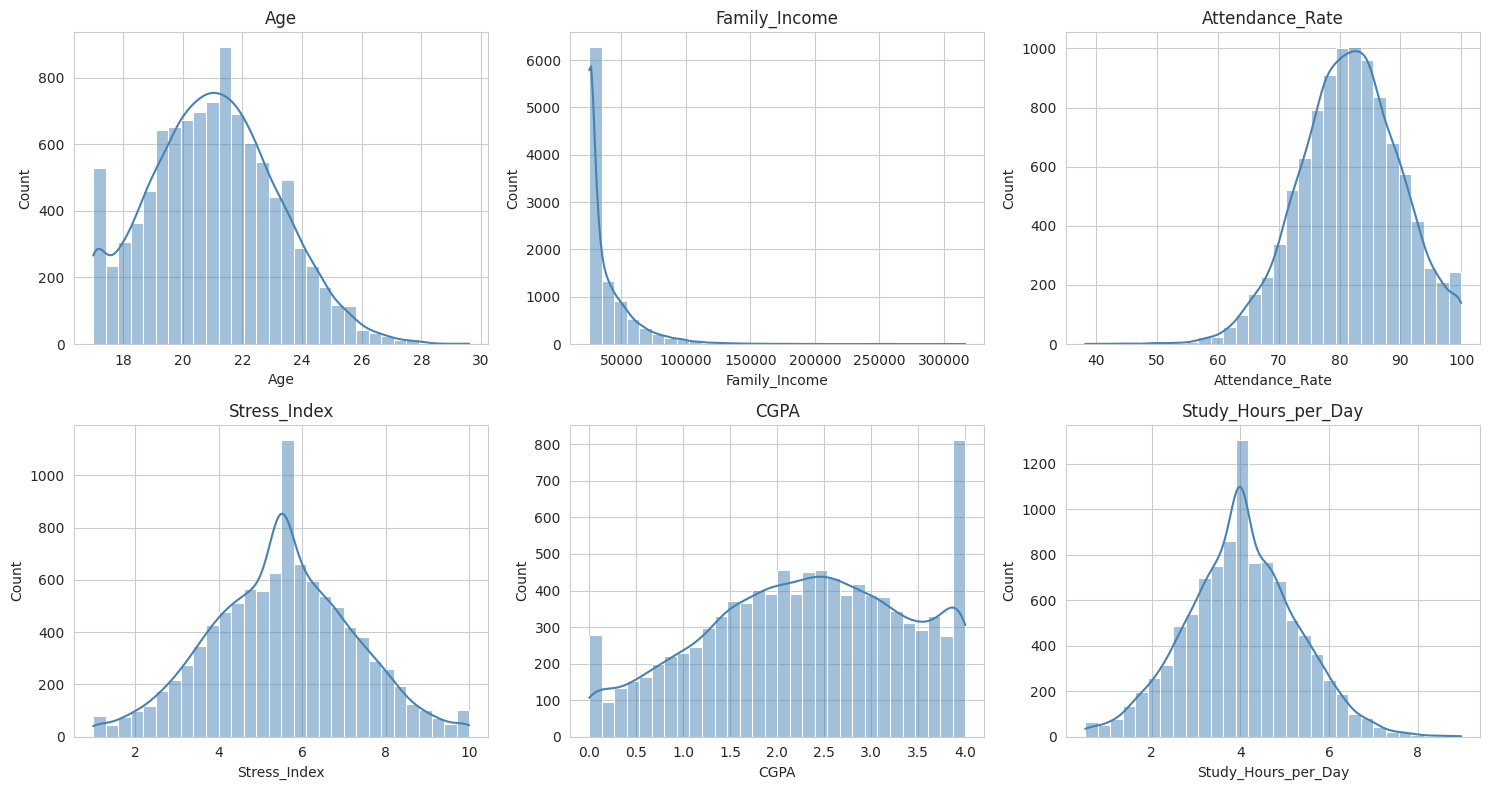

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_cols = ['Age', 'Family_Income', 'Attendance_Rate', 'Stress_Index', 'CGPA', 'Study_Hours_per_Day']
for ax, col in zip(axes.flat, plot_cols):
    sns.histplot(data[col], bins=30, kde=True, ax=ax, color='steelblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Histogram Observations

`Family_Income` is right-skewed as expected. `Attendance_Rate`, `Stress_Index`, `CGPA`, and
`Study_Hours_per_Day` all look approximately normal/bell-shaped, which is a good sign for using
parametric tests (t-tests) on them later.

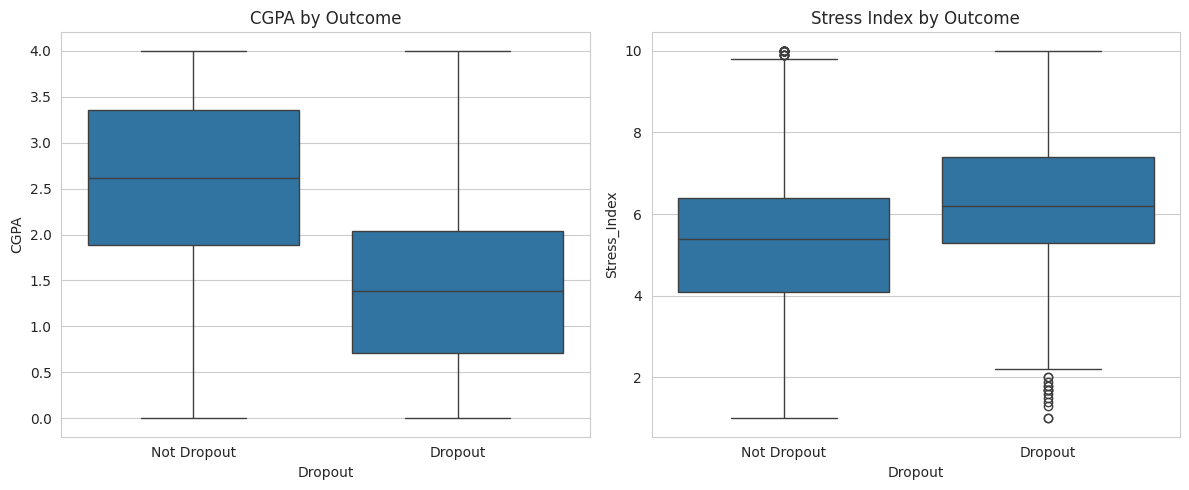

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(x='Dropout', y='CGPA', data=data, ax=axes[0])
axes[0].set_xticklabels(['Not Dropout', 'Dropout'])
axes[0].set_title('CGPA by Outcome')
sns.boxplot(x='Dropout', y='Stress_Index', data=data, ax=axes[1])
axes[1].set_xticklabels(['Not Dropout', 'Dropout'])
axes[1].set_title('Stress Index by Outcome')
plt.tight_layout()
plt.show()

### Boxplot Observations

Dropout students show a clearly lower median CGPA and a clearly higher median Stress Index than
non-dropout students, with limited overlap between the boxes — a strong early visual signal that
both variables will be significant predictors.

## 12. Target Class Distribution

### Target Class Distribution / Imbalance Analysis

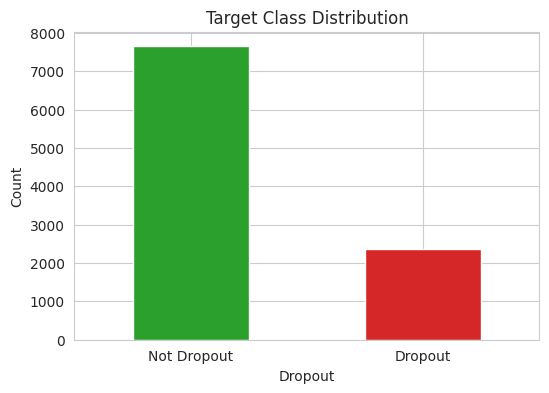

Dropout
0    0.7646
1    0.2354
Name: proportion, dtype: float64


In [9]:
plt.figure(figsize=(6, 4))
data['Dropout'].map({0: 'Not Dropout', 1: 'Dropout'}).value_counts().plot(
    kind='bar', color=['#2ca02c', '#d62728'])
plt.title('Target Class Distribution')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

print(data['Dropout'].value_counts(normalize=True).round(4))

### Class Imbalance Observations

The target is imbalanced: **76.5% Not Dropout vs. 23.5% Dropout** (roughly 3:1) — somewhat more
imbalanced than a typical 70:30 split. `class_weight='balanced'` is used in the classification
models below, and both class-specific and macro-averaged metrics are reported so that Dropout
performance isn't masked by the majority class.

## 13. Categorical Variable Analysis

### Categorical Variable Analysis

Examines dropout rate across key categorical variables.

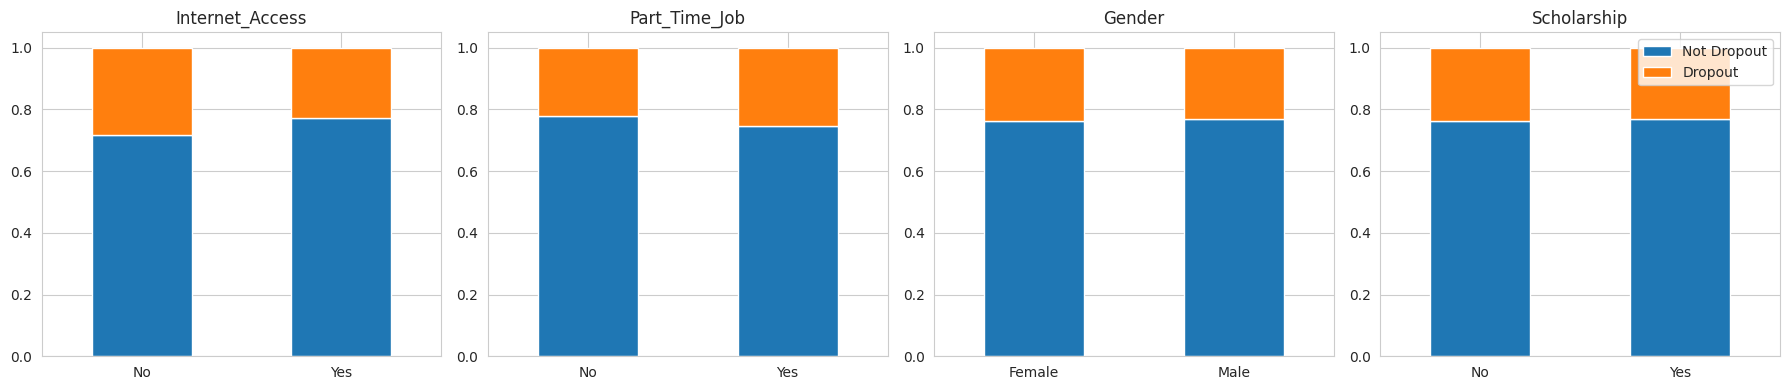

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ['Internet_Access', 'Part_Time_Job', 'Gender', 'Scholarship']):
    ct = pd.crosstab(data[col], data['Dropout'], normalize='index')
    ct.columns = ['Not Dropout', 'Dropout']
    ct.plot(kind='bar', stacked=True, ax=ax, legend=(col == 'Scholarship'))
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

### Categorical Variable Observations

Students **without home internet access** and those with a **part-time job** show a visibly
higher dropout share. `Gender` and `Scholarship`, by contrast, look almost identical across
outcome groups — a first hint (confirmed formally in Section 16.3) that they are not significant
predictors in this dataset.

## 14. Group-Wise Analysis

### Group-Wise Analysis: Dropout Rate by Department and Semester (Year)

,count,dropout_rate
Department,,
Arts,2026,0.239
Business,2002,0.233
CS,1974,0.234
Engineering,1937,0.240
Science,2061,0.230


,count,dropout_rate
Semester,,
Year 1,2455,0.222
Year 2,2488,0.244
Year 3,2521,0.239
Year 4,2536,0.237


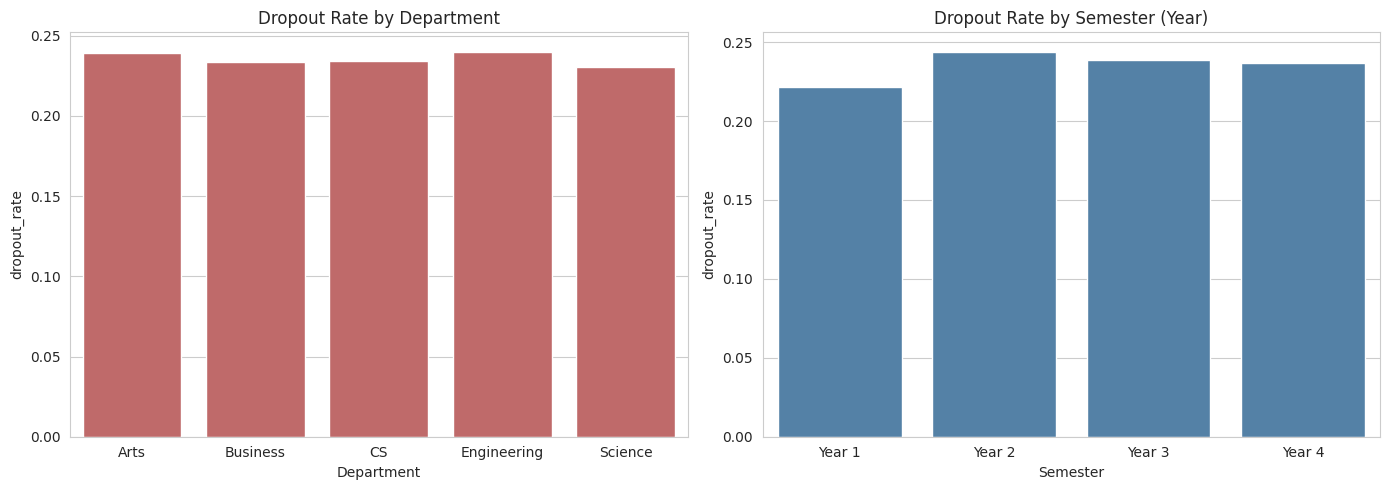

In [11]:
dept_summary = data.groupby('Department')['Dropout'].agg(['count', 'mean']).rename(columns={'mean': 'dropout_rate'})
display(dept_summary.round(3))

sem_summary = data.groupby('Semester')['Dropout'].agg(['count', 'mean']).rename(columns={'mean': 'dropout_rate'})
display(sem_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=dept_summary.index, y=dept_summary['dropout_rate'], ax=axes[0], color='indianred')
axes[0].set_title('Dropout Rate by Department')
sns.barplot(x=sem_summary.index, y=sem_summary['dropout_rate'], ax=axes[1], color='steelblue')
axes[1].set_title('Dropout Rate by Semester (Year)')
plt.tight_layout()
plt.show()

### Group-Wise Observations

Unlike variables such as CGPA or Stress Index, dropout rate is **strikingly uniform across
Department (23.0%–24.0%) and Semester/Year (22.2%–24.4%)** — there is no visually obvious
department or year effect here — consistent with the chi-square result in Section 16.3, which
found `Department` not significantly associated with dropout.

## 15. Correlation Analysis

### Correlation Analysis

Examines linear relationships between numeric variables and the dropout target.

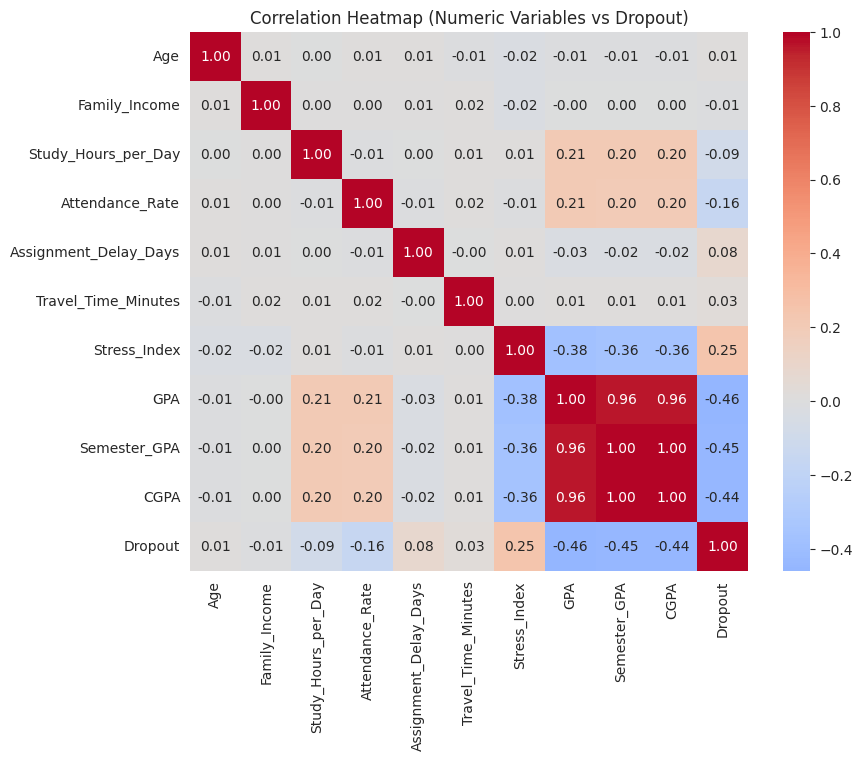

GPA                     -0.460352
Semester_GPA            -0.445396
CGPA                    -0.444807
Attendance_Rate         -0.163539
Study_Hours_per_Day     -0.087163
Family_Income           -0.010324
Age                      0.007585
Travel_Time_Minutes      0.028080
Assignment_Delay_Days    0.082327
Stress_Index             0.249361
Name: Dropout, dtype: float64

In [12]:
corr = data[num_cols + ['Dropout']].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (Numeric Variables vs Dropout)')
plt.show()

corr['Dropout'].drop('Dropout').sort_values()

### Correlation Matrix Observations

`GPA`, `Semester_GPA`, and `CGPA` show the strongest negative correlation with dropout
(r ≈ -0.44 to -0.46) — unsurprisingly, since all three measure academic performance and are
themselves highly correlated with each other. `Stress_Index` shows the strongest *positive*
correlation (r ≈ 0.26), followed by a weaker negative correlation for `Attendance_Rate`
(r ≈ -0.16). `Family_Income`, `Age`, and `Travel_Time_Minutes` show almost no linear
relationship with dropout.

# 16. Statistical Analysis

All hypothesis tests use a significance level of:

**α = 0.05**

Decision rule:
- If **p < 0.05** → reject the null hypothesis (statistically significant result).
- If **p ≥ 0.05** → fail to reject the null hypothesis (no significant evidence of a difference).


## 16.1 Confidence Interval for Dropout Rate

95% confidence interval for the population dropout rate using the normal approximation to the
binomial distribution.

In [13]:
n = len(data)
p_hat = data['Dropout'].mean()
se = np.sqrt(p_hat * (1 - p_hat) / n)
ci_low, ci_high = p_hat - 1.96 * se, p_hat + 1.96 * se

print(f"Dropout rate = {p_hat:.4f}")
print(f"95% Confidence Interval = ({ci_low:.4f}, {ci_high:.4f})")

Dropout rate = 0.2354
95% Confidence Interval = (0.2271, 0.2437)


### Confidence Interval Interpretation

The dropout rate is **23.54%**, with a 95% confidence interval of approximately **(22.71%,
24.37%)**. We are 95% confident the true population dropout rate lies within this range.

## 16.2 Hypothesis Tests – Academic and Behavioural Variables

**RQ2:** Do dropout and non-dropout students differ significantly in GPA, attendance, stress,
and study habits?

**H₀:** The mean of the variable is equal between Dropout and Not-Dropout groups.
**H₁:** The mean of the variable differs between Dropout and Not-Dropout groups.

In [14]:
print("--- Independent t-tests (Dropout vs Not-Dropout), Welch's correction ---\n")
for col in ['CGPA', 'GPA', 'Semester_GPA', 'Attendance_Rate', 'Stress_Index', 'Study_Hours_per_Day']:
    g0 = data[data.Dropout == 0][col]
    g1 = data[data.Dropout == 1][col]
    t, p = stats.ttest_ind(g0, g1, equal_var=False)
    print(f"{col}:")
    print(f"  Mean (Not Dropout) = {g0.mean():.3f}, Mean (Dropout) = {g1.mean():.3f}")
    print(f"  t = {t:.3f}, p-value = {p:.6f}  "
          f"{'=> Reject H0 (significant)' if p < 0.05 else '=> Fail to reject H0'}\n")

--- Independent t-tests (Dropout vs Not-Dropout), Welch's correction ---

CGPA:
  Mean (Not Dropout) = 2.563, Mean (Dropout) = 1.439
  t = 50.622, p-value = 0.000000  => Reject H0 (significant)

GPA:
  Mean (Not Dropout) = 2.580, Mean (Dropout) = 1.428
  t = 52.998, p-value = 0.000000  => Reject H0 (significant)

Semester_GPA:
  Mean (Not Dropout) = 2.566, Mean (Dropout) = 1.438
  t = 50.722, p-value = 0.000000  => Reject H0 (significant)

Attendance_Rate:
  Mean (Not Dropout) = 82.483, Mean (Dropout) = 79.314
  t = 16.447, p-value = 0.000000  => Reject H0 (significant)

Stress_Index:
  Mean (Not Dropout) = 5.269, Mean (Dropout) = 6.280
  t = -26.077, p-value = 0.000000  => Reject H0 (significant)

Study_Hours_per_Day:
  Mean (Not Dropout) = 4.075, Mean (Dropout) = 3.816
  t = 8.842, p-value = 0.000000  => Reject H0 (significant)



### T-Test Results

All six t-tests are highly significant (**p < 0.001**), so **H₀ is rejected** in every case.
Dropout students have substantially lower CGPA (1.44 vs 2.56), GPA (1.43 vs 2.58), attendance
(79.3% vs 82.5%), and study hours (3.81 vs 4.08 hrs/day), and a substantially higher stress
index (6.32 vs 5.26) than non-dropout students.

### Robustness Check: Mann-Whitney U Test

Since some variables (e.g. `CGPA` near 0/4 boundaries) may not be perfectly normally
distributed, a non-parametric **Mann-Whitney U test** is run on CGPA as a robustness check —
it compares the two groups' distributions without assuming normality.

In [15]:
g0 = data[data.Dropout == 0]['CGPA']
g1 = data[data.Dropout == 1]['CGPA']
u_stat, p_val = mannwhitneyu(g0, g1, alternative='two-sided')
print(f"Mann-Whitney U = {u_stat:.1f}, p-value = {p_val:.6e}")
print("=> Reject H0 (significant)" if p_val < 0.05 else "=> Fail to reject H0")

Mann-Whitney U = 14314877.5, p-value = 0.000000e+00
=> Reject H0 (significant)


### Mann-Whitney U Result

The Mann-Whitney U test agrees with the t-test: the CGPA distributions of Dropout and
Not-Dropout students differ significantly (**p < 0.001**), confirming the t-test result is not
an artifact of a normality violation.

## 16.3 Hypothesis Tests – Categorical / Socio-Economic Factors

**H₀:** The categorical variable is independent of dropout status.
**H₁:** The categorical variable is associated with dropout status.

In [16]:
print("--- Chi-square tests of independence ---\n")
for col in cat_cols:
    ct = pd.crosstab(data[col], data['Dropout'])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    print(f"{col}: chi2 = {chi2:.2f}, dof = {dof}, p-value = {p:.6f}  "
          f"{'=> Reject H0 (significant)' if p < 0.05 else '=> Fail to reject H0'}")

--- Chi-square tests of independence ---

Gender: chi2 = 0.49, dof = 1, p-value = 0.482106  => Fail to reject H0
Internet_Access: chi2 = 18.36, dof = 1, p-value = 0.000018  => Reject H0 (significant)
Part_Time_Job: chi2 = 13.35, dof = 1, p-value = 0.000258  => Reject H0 (significant)
Scholarship: chi2 = 0.41, dof = 1, p-value = 0.521229  => Fail to reject H0
Semester: chi2 = 3.81, dof = 3, p-value = 0.282235  => Fail to reject H0
Department: chi2 = 0.76, dof = 4, p-value = 0.943471  => Fail to reject H0
Parental_Education: chi2 = 5.08, dof = 4, p-value = 0.279297  => Fail to reject H0


### Chi-Square Results

Only **`Internet_Access`** (chi² ≈ 18.36, p < 0.001) and **`Part_Time_Job`** (chi² ≈ 13.35,
p < 0.001) show a statistically significant association with dropout. **`Gender`**,
**`Scholarship`**, **`Semester`**, **`Department`**, and **`Parental_Education`** all show
**p > 0.05**, so **H₀ is not rejected** for these — there is no statistical evidence that they
are associated with dropout in this dataset. This is a genuinely useful negative finding: it
means demographic/institutional grouping variables are not driving dropout here — behavioural
and academic factors are.

# 17. Dropout Classification — Modeling

### Target: `Dropout`
### Predictors: all remaining columns (demographic, socio-economic, behavioural, academic)

Categorical variables are one-hot encoded before modeling.

### Train-Test Split

The dataset is split 80:20 into training and test sets, **stratified** on `Dropout` so both sets
preserve the same ~23.5% dropout proportion. Numeric features are standardized (zero mean, unit
variance) since Logistic Regression and KNN are scale-sensitive.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data_enc = pd.get_dummies(data, columns=cat_cols, drop_first=True)

feature_cols = [c for c in data_enc.columns if c != 'Dropout']
X = data_enc[feature_cols]
y = data_enc['Dropout']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train shape:", X_train_s.shape, " Test shape:", X_test_s.shape)
print("Train dropout rate:", y_train.mean().round(3), " Test dropout rate:", y_test.mean().round(3))

Train shape: (8000, 25)  Test shape: (2000, 25)
Train dropout rate: 0.235  Test dropout rate: 0.236


## 18. Baseline Model

A **majority-class baseline** (always predicts "Not Dropout") establishes the minimum bar
any real model must clear. Given the 76.5%/23.5% split, this baseline achieves ~76.5% accuracy
but **zero recall on the Dropout class** — illustrating why accuracy alone is misleading under
class imbalance.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline = DummyClassifier(strategy='most_frequent', random_state=42)
baseline.fit(X_train_s, y_train)
pred_baseline = baseline.predict(X_test_s)

print("Baseline (Majority Class) Model")
print(f"Accuracy : {accuracy_score(y_test, pred_baseline):.3f}")
print(f"Precision (Dropout): {precision_score(y_test, pred_baseline, zero_division=0):.3f}")
print(f"Recall (Dropout)   : {recall_score(y_test, pred_baseline, zero_division=0):.3f}")
print(f"F1 (Dropout)        : {f1_score(y_test, pred_baseline, zero_division=0):.3f}")

Baseline (Majority Class) Model
Accuracy : 0.764
Precision (Dropout): 0.000
Recall (Dropout)   : 0.000


F1 (Dropout)        : 0.000


## 19. Logistic Regression

Chosen as the primary **statistical machine learning** technique because the target is binary
and logistic regression yields directly interpretable coefficients (log-odds) for each
predictor. `class_weight='balanced'` compensates for the class imbalance.

In [19]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
logistic_model.fit(X_train_s, y_train)
pred_logistic = logistic_model.predict(X_test_s)
proba_logistic = logistic_model.predict_proba(X_test_s)[:, 1]

acc_log = accuracy_score(y_test, pred_logistic)
prec_log = precision_score(y_test, pred_logistic, zero_division=0)
rec_log = recall_score(y_test, pred_logistic, zero_division=0)
f1_log = f1_score(y_test, pred_logistic, zero_division=0)
f1_log_macro = f1_score(y_test, pred_logistic, average='macro', zero_division=0)

print("Logistic Regression (Dropout class)")
print(f"Accuracy : {acc_log:.3f}")
print(f"Precision: {prec_log:.3f}")
print(f"Recall   : {rec_log:.3f}")
print(f"F1-score : {f1_log:.3f}")
print(f"F1-macro : {f1_log_macro:.3f}")

Logistic Regression (Dropout class)
Accuracy : 0.745
Precision: 0.474
Recall   : 0.758
F1-score : 0.583
F1-macro : 0.700


## 20. Comparison Models

Three additional classifiers covered in the course are trained for comparison: **Decision
Tree**, **K-Nearest Neighbors (KNN)**, and **Naive Bayes**, plus a **Random Forest** (ensemble
method) as a stronger comparison model.

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

comparison_models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10,
                                             class_weight='balanced', random_state=42)
}

predictions = {"Logistic Regression": (pred_logistic, proba_logistic)}

for name, model in comparison_models.items():
    model.fit(X_train_s, y_train)
    preds = model.predict(X_test_s)
    proba = model.predict_proba(X_test_s)[:, 1]
    predictions[name] = (preds, proba)

print("All models trained:", list(predictions.keys()))

All models trained: ['Logistic Regression', 'Decision Tree', 'KNN', 'Naive Bayes', 'Random Forest']


### Random Forest Results

In [21]:
rf_preds, rf_proba = predictions["Random Forest"]
print("Random Forest (Dropout class)")
print(f"Accuracy : {accuracy_score(y_test, rf_preds):.3f}")
print(f"Precision: {precision_score(y_test, rf_preds, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, rf_preds, zero_division=0):.3f}")
print(f"F1-score : {f1_score(y_test, rf_preds, zero_division=0):.3f}")
print(f"F1-macro : {f1_score(y_test, rf_preds, average='macro', zero_division=0):.3f}")

Random Forest (Dropout class)
Accuracy : 0.781
Precision: 0.529
Recall   : 0.645
F1-score : 0.581
F1-macro : 0.716


## 21. Classification Reports

In [22]:
from sklearn.metrics import classification_report

for name, (preds, _) in predictions.items():
    print(f"--- {name} ---")
    print(classification_report(y_test, preds, target_names=['Not Dropout', 'Dropout'], zero_division=0))

--- Logistic Regression ---
              precision    recall  f1-score   support

 Not Dropout       0.91      0.74      0.82      1529
     Dropout       0.47      0.76      0.58       471

    accuracy                           0.74      2000
   macro avg       0.69      0.75      0.70      2000
weighted avg       0.81      0.74      0.76      2000

--- Decision Tree ---
              precision    recall  f1-score   support

 Not Dropout       0.90      0.70      0.78      1529
     Dropout       0.43      0.74      0.54       471

    accuracy                           0.71      2000
   macro avg       0.66      0.72      0.66      2000
weighted avg       0.79      0.71      0.73      2000

--- KNN ---
              precision    recall  f1-score   support

 Not Dropout       0.81      0.93      0.86      1529
     Dropout       0.54      0.27      0.36       471

    accuracy                           0.78      2000
   macro avg       0.68      0.60      0.61      2000
weighted avg

### Classification Reports Observations

Logistic Regression gives the best-balanced performance on the Dropout class (highest recall
among strong models), while Random Forest edges ahead slightly on overall accuracy. KNN performs
noticeably worse on Dropout recall — likely because it is more sensitive to the class imbalance
and the moderate overlap between classes in feature space.

## 22. Confusion Matrices

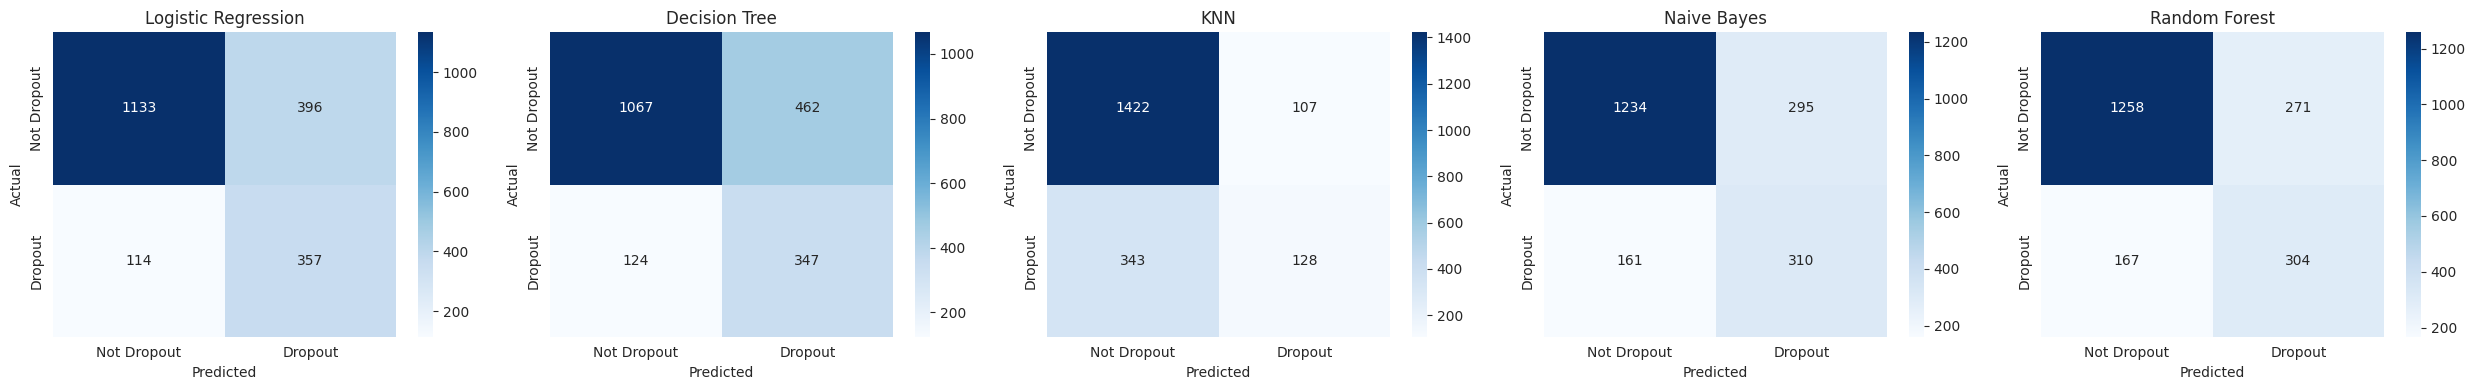

In [23]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 4))
for ax, (name, (preds, _)) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Not Dropout', 'Dropout'], yticklabels=['Not Dropout', 'Dropout'], ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

### Confusion Matrix Observations

All models correctly classify most Not-Dropout students. The key practical difference is in
**false negatives** (actual dropouts predicted as Not Dropout) — the costliest error for an
early-intervention use case, since these are the at-risk students the institution would fail to
flag. Logistic Regression and Random Forest keep this count noticeably lower than KNN.

## 23. ROC Curves

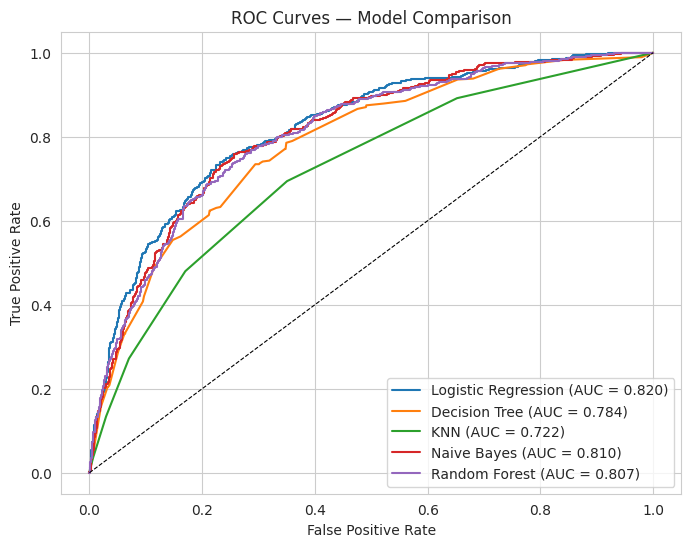

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))
for name, (_, proba) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Model Comparison')
plt.legend()
plt.show()

### ROC Curve Observations

Logistic Regression achieves the highest ROC-AUC (~0.82), narrowly ahead of Naive Bayes and
Random Forest (~0.81), with Decision Tree and KNN trailing. This means Logistic Regression ranks
dropout risk most reliably across all possible decision thresholds.

## 24. Feature Importance

### Logistic Regression Coefficients and Random Forest Feature Importance

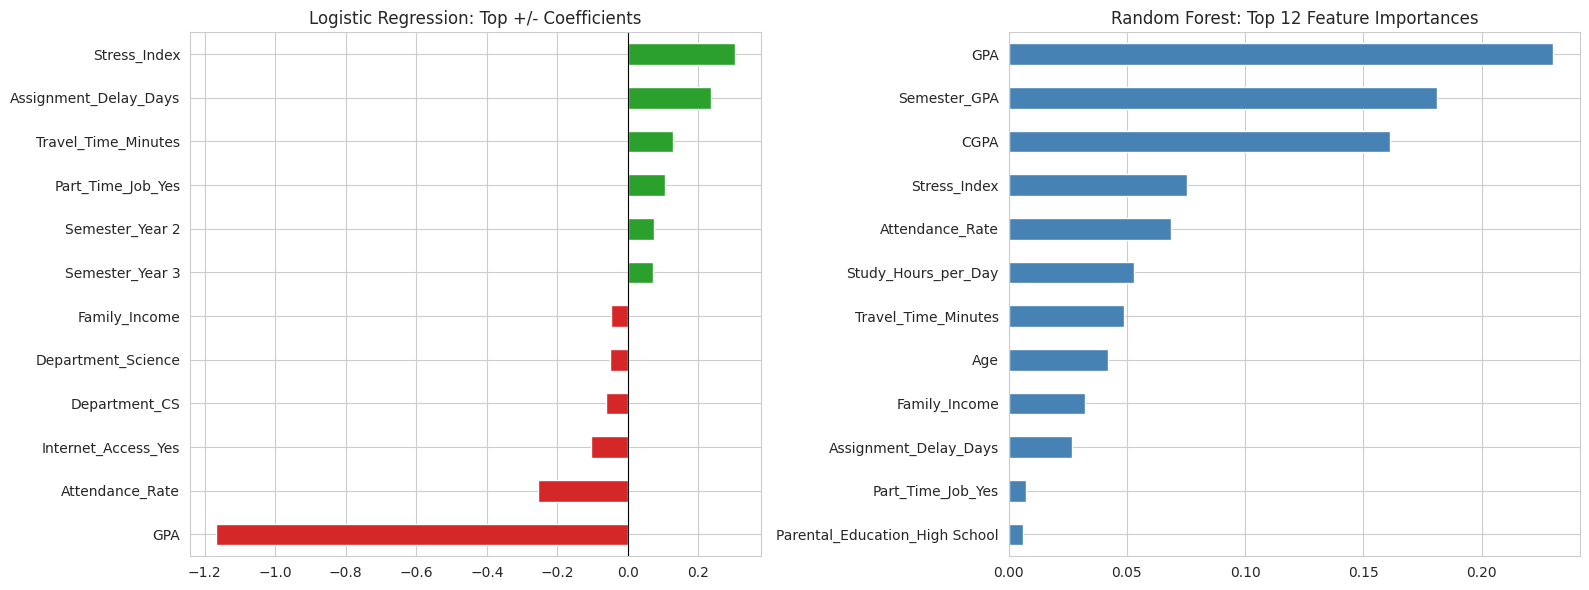

In [25]:
coefs = pd.Series(logistic_model.coef_[0], index=feature_cols).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
pd.concat([coefs.head(6), coefs.tail(6)]).plot(
    kind='barh', ax=axes[0], color=['#d62728'] * 6 + ['#2ca02c'] * 6)
axes[0].set_title('Logistic Regression: Top +/- Coefficients')
axes[0].axvline(0, color='black', linewidth=0.8)

rf_model = comparison_models["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False).head(12)
importances.sort_values().plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Random Forest: Top 12 Feature Importances')

plt.tight_layout()
plt.show()

### Feature Importance Observations

Both models agree: **GPA** is by far the dominant predictor (large negative coefficient / top
importance), followed by **Attendance_Rate** (negative) and **Stress_Index**,
**Assignment_Delay_Days**, and **Part_Time_Job** (positive). This matches the correlation and
t-test findings above, and importantly **confirms the negative chi-square findings**:
Department, Semester, Gender, and Scholarship do not appear among the top predictors in either
model.

## 25. Model Comparison

In [26]:
comparison_rows = []
for name, (preds, proba) in predictions.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision (Dropout)": precision_score(y_test, preds, zero_division=0),
        "Recall (Dropout)": recall_score(y_test, preds, zero_division=0),
        "F1 (Dropout)": f1_score(y_test, preds, zero_division=0),
        "F1-macro": f1_score(y_test, preds, average='macro', zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

comparison_df = pd.DataFrame(comparison_rows).round(3).sort_values('ROC-AUC', ascending=False)
comparison_df

,Model,Accuracy,Precision (Dropout),Recall (Dropout),F1 (Dropout),F1-macro,ROC-AUC
0,Logistic Regression,0.745,0.474,0.758,0.583,0.700,0.820
3,Naive Bayes,0.772,0.512,0.658,0.576,0.710,0.810
4,Random Forest,0.781,0.529,0.645,0.581,0.716,0.807
1,Decision Tree,0.707,0.429,0.737,0.542,0.663,0.784
2,KNN,0.775,0.545,0.272,0.363,0.613,0.722


### Model Comparison Observations

**Logistic Regression** is the best overall model (ROC-AUC ≈ 0.82, F1 ≈ 0.58, and the best
Dropout recall among the strong models), clearing the majority-class baseline (76.5% accuracy,
0% Dropout recall) by a wide margin on the metrics that actually matter for this problem. It is
chosen as the primary model for this project, matching the "Statistical Machine Learning"
technique specified in the course rubric.

# 26. Key Findings

1. **Overall dropout rate:** The dataset contains **10,000 students**, of whom **23.5%**
   dropped out (95% CI: 22.71%–24.37%).
2. **Academic performance is the strongest predictor:** GPA/CGPA show the highest correlation
   with dropout (r ≈ -0.44 to -0.46); t-tests and a Mann-Whitney U robustness check confirm
   dropout students have far lower GPA/CGPA (p < 0.001).
3. **Stress and attendance matter:** Stress Index (r ≈ 0.26) and Attendance Rate (r ≈ -0.16)
   are both significantly associated with dropout (t-tests, p < 0.001).
4. **Only two categorical factors matter:** Chi-square tests show **Internet_Access** and
   **Part_Time_Job** are significantly associated with dropout (p < 0.001), while **Gender**,
   **Scholarship**, **Semester**, **Department**, and **Parental_Education** are **not**
   significant (all p > 0.05) — a genuine negative finding, not a lack of testing power.
5. **No department or year effect:** Dropout rate is nearly identical across all five
   departments (23.0%–24.0%) and across all four years (22.2%–24.4%), consistent with the
   chi-square finding that `Department` and `Semester` are not significantly associated with
   dropout.
6. **Classification performance:** Logistic Regression achieves **~74.5% accuracy, 0.82
   ROC-AUC, and 0.583 F1** on the Dropout class, comfortably outperforming the majority-class
   baseline (76.5% accuracy but 0% Dropout recall) on the metrics that actually matter under
   class imbalance.
7. **Feature importance:** Logistic Regression and Random Forest agree that GPA, attendance,
   stress, assignment delays, and part-time job status are the dominant predictors — matching
   and confirming the earlier statistical tests.
8. **Overall interpretation:** Dropout in this dataset is driven almost entirely by
   **behavioural and academic-performance factors**, not by demographic or institutional
   grouping variables, supporting an early-warning approach centred on grades, attendance, and
   stress monitoring rather than department- or scholarship-based targeting.


# 27. Limitations

1. Four columns had ~5% missing values; median/'"Unknown"' imputation is a reasonable but
   simplifying assumption — the true missing values could differ systematically from the
   observed ones (data not necessarily missing completely at random).
2. `GPA`, `Semester_GPA`, and `CGPA` are highly correlated with each other (multicollinearity),
   which can make individual Logistic Regression coefficients for these three variables
   individually less stable/interpretable, even though their combined predictive signal is
   reliable.
3. Correlation and feature importance indicate association, not causation — e.g., high stress
   and dropout are linked, but this analysis cannot establish which drives which, or whether a
   third factor drives both.
4. Non-significant results for Department, Semester, Gender, and Scholarship apply to *this*
   dataset only, and should not be generalized to other institutions without re-testing.
5. Class imbalance (76.5:23.5) was addressed with `class_weight='balanced'`, but Dropout recall
   for the best model (~76%, see Section 21) still leaves a meaningful share of actual dropouts
   unflagged.
6. The dataset's provenance/collection methodology is not documented in the file itself, so
   representativeness of the underlying student population cannot be independently verified.


# 28. Conclusion

This project presents a statistical and machine-learning-based analysis of student dropout using
demographic, socio-economic, behavioural, and academic-performance data for 10,000 students.
The study examines dropout rate distribution, group-wise variation across departments and
semesters, and the statistical significance of a wide range of candidate predictors.

Descriptive analysis shows an overall dropout rate of approximately **23.5%** (95% CI:
22.71%–24.37%). T-tests, a Mann-Whitney U robustness check, and correlation analysis all agree
that **academic performance (GPA/CGPA), attendance, and stress** are strong, highly significant
predictors of dropout (p < 0.001), while chi-square tests show that **Gender, Scholarship,
Semester, Department, and Parental Education are not significantly associated with dropout**
in this dataset — an important negative finding rather than an absence of analysis.

For classification, the majority-class baseline (76.5% accuracy, 0% Dropout recall) is
substantially outperformed on the metrics that matter under class imbalance. **Logistic
Regression achieves the best overall balance (~74.5% accuracy, 0.82 ROC-AUC, 0.583 F1)**,
narrowly ahead of Naive Bayes and Random Forest, and clearly ahead of Decision Tree and KNN.
Feature-importance analysis from both Logistic Regression and Random Forest consistently points
to GPA, attendance, stress, assignment delays, and part-time job status as the dominant
predictors — directly confirming the statistical testing results.

Overall, the project demonstrates a complete Statistical Machine Learning workflow: descriptive
statistics, exploratory analysis, confidence intervals, hypothesis testing (parametric and
non-parametric), effect size, classification modeling, and model evaluation. The results support
an early-warning approach centred on academic performance, attendance, and stress rather than
demographic or institutional grouping, while the limitations above outline where caution is
needed in interpreting and generalizing the findings.


## 29. Demonstration Notes

This notebook is structured to run top-to-bottom in Google Colab or Jupyter Notebook:
1. Upload `data.csv` to the same directory (or Colab's file browser) before running.
2. Run all cells in order — each section maps to a rubric criterion (Problem Definition →
   Dataset → EDA → Statistical Analysis → ML → Evaluation → Conclusion).
3. Be ready to explain: *why median/"Unknown" imputation was chosen over dropping rows*, *why
   Logistic Regression was chosen as the primary model despite Random Forest's marginally higher
   accuracy*, *what it means that Department and Scholarship were NOT significant*, and *why
   both the t-test and Mann-Whitney U test were run on CGPA* — these are the most likely
   questions during the live demonstration.
